# Project 6: Predicting River Baseflow with Multiple Linear Regression

**Dataset:** RRCA baseflow dataset (Republican River basin). Each row is one river segment in one month, from September 1939 to August 2000.

**Goal:** Use multiple linear regression to predict observed baseflow and to understand how climate, irrigation pumping, location, and time relate to it.


In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, MUTED, GRID, SURF = '#0b0b0b', '#898781', '#e1e0d9', '#fcfcfb'
SEQ = ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b']
plt.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF,
    'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'text.color': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.family': 'sans-serif', 'font.size': 11, 'axes.titlesize': 12})

## 1. Load and prepare the data

The raw `Date` column counts days since 01/01/0000. Subtracting 693963 converts it to days since Jan 1, 1900, which we then turn into a real calendar date. Irrigation pumping is stored as zero or negative values, where a more negative value means more groundwater was pumped out near that segment.


In [2]:
df = pd.read_csv('RRCA_baseflow.csv')
df['Date'] = df['Date'] - 693963
df['date'] = pd.to_datetime('1900-01-01') + pd.to_timedelta(df['Date'], unit='D')
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
print(df.shape)
print('Date range:', df['date'].min().date(), 'to', df['date'].max().date())
print('Number of segments:', df['Segment_id'].nunique())
print('Missing values:', int(df.isnull().sum().sum()))
df.head()

(15591, 11)
Date range: 1939-09-30 to 2000-08-30
Number of segments: 42
Missing values: 0


,Date,Segment_id,x,y,Evapotranspiration,Precipitation,Irrigation_pumping,Observed,date,year,month
0,16769,144,1086190,14476800,0.59,18.99,0.0,0.145161,1945-11-30,1945,11
1,16800,144,1086190,14476800,0.97,29.63,0.0,0.445161,1945-12-31,1945,12
2,16828,144,1086190,14476800,1.34,29.63,0.0,1.332203,1946-01-28,1946,1
3,16859,144,1086190,14476800,1.79,29.63,0.0,2.932203,1946-02-28,1946,2
4,16889,144,1086190,14476800,8.23,29.63,0.0,3.728689,1946-03-30,1946,3


In [3]:
df[['Evapotranspiration', 'Precipitation', 'Irrigation_pumping', 'Observed']].describe().round(2)

,Evapotranspiration,Precipitation,Irrigation_pumping,Observed
count,15591.00,15591.00,15591.00,15591.00
mean,2.69,14.92,-0.09,23.99
std,3.17,10.51,0.27,56.28
min,0.00,0.00,-3.16,-22.00
25%,0.00,0.00,-0.01,1.99
50%,1.04,17.49,0.00,7.70
75%,5.34,22.37,0.00,22.80
max,12.10,40.38,0.00,747.80


## 2. Exploratory analysis

First we look at each candidate predictor against observed baseflow. No single input has a clean linear relationship with baseflow when all segments are pooled together.


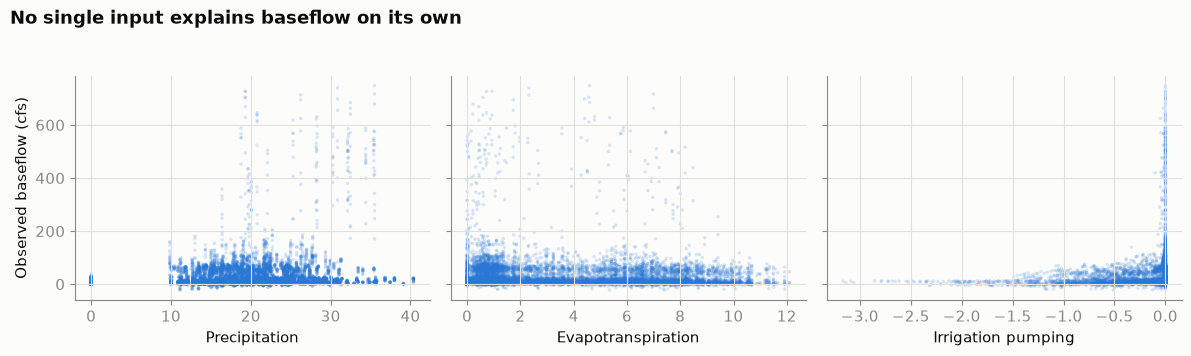

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, col, label in zip(axes,
        ['Precipitation', 'Evapotranspiration', 'Irrigation_pumping'],
        ['Precipitation', 'Evapotranspiration', 'Irrigation pumping']):
    ax.scatter(df[col], df['Observed'], s=6, alpha=0.18, color=BLUE, edgecolors='none')
    ax.set_xlabel(label)
axes[0].set_ylabel('Observed baseflow (cfs)')
fig.suptitle('No single input explains baseflow on its own', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

Baseflow levels differ enormously between segments. The largest segments average hundreds of cfs while the smallest average under 1 cfs. This tells us segment identity will matter a lot for prediction.


In [5]:
seg_stats = df.groupby('Segment_id')['Observed'].agg(['mean', 'std', 'count'])
seg_stats.sort_values('mean', ascending=False).head(8).round(2)

,mean,std,count
Segment_id,,,
256,393.72,185.46,119
239,374.03,175.46,119
194,106.25,53.47,72
157,90.18,12.82,133
188,77.85,21.12,576
205,71.88,44.53,116
53,61.82,54.09,240
130,54.55,10.20,732


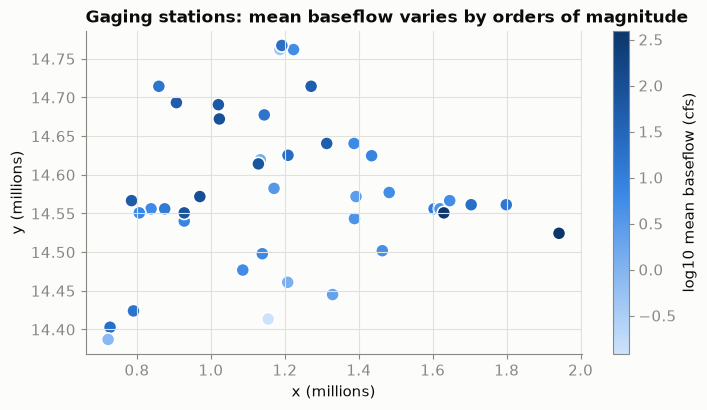

In [6]:
segpos = df.groupby('Segment_id').agg(x=('x', 'mean'), y=('y', 'mean'), bf=('Observed', 'mean')).reset_index()
fig, ax = plt.subplots(figsize=(8, 4.2))
v = np.log10(segpos['bf'].clip(lower=0.1))
cmap = matplotlib.colors.LinearSegmentedColormap.from_list('seq', SEQ)
sc = ax.scatter(segpos['x'] / 1e6, segpos['y'] / 1e6, c=v, s=90, cmap=cmap,
                edgecolors='white', linewidths=1.2)
cb = fig.colorbar(sc, ax=ax)
cb.set_label('log10 mean baseflow (cfs)')
ax.set_xlabel('x (millions)')
ax.set_ylabel('y (millions)')
ax.set_title('Gaging stations: mean baseflow varies by orders of magnitude', loc='left', fontweight='bold')
plt.show()

### Baseflow over time

A naive annual mean over all rows is misleading because the set of gaged segments changes over the years, and several very large segments only appear early in the record. To see a real trend we restrict to the 10 segments that have records from the early 1940s through 1999 and track the same set of rivers the whole time. We also drop the year 2000, which only runs through August and would bias an annual mean.


Segments gaged across the whole period: [59, 65, 96, 130, 144, 145, 152, 171, 178, 189]


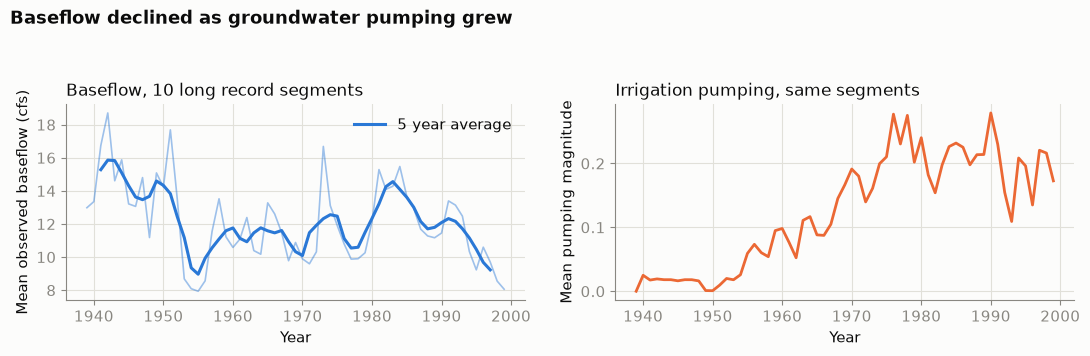

In [7]:
span = df.groupby('Segment_id')['year'].agg(['min', 'max'])
cohort = span[(span['min'] <= 1945) & (span['max'] >= 1999)].index
print('Segments gaged across the whole period:', list(cohort))
sub = df[df['Segment_id'].isin(cohort)]
ann = sub.groupby('year').agg(bf=('Observed', 'mean'), pump=('Irrigation_pumping', 'mean')).reset_index()
ann = ann[ann['year'] <= 1999]  # the record ends in Aug 2000, so 2000 is a partial year
ann['bf5'] = ann['bf'].rolling(5, center=True).mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(ann['year'], ann['bf'], color=BLUE, lw=1.2, alpha=0.45)
axes[0].plot(ann['year'], ann['bf5'], color=BLUE, lw=2.2, label='5 year average')
axes[0].set_ylabel('Mean observed baseflow (cfs)')
axes[0].set_xlabel('Year')
axes[0].set_title('Baseflow, 10 long record segments', loc='left')
axes[0].legend(frameon=False)
axes[1].plot(ann['year'], -ann['pump'], color=ORANGE, lw=2)
axes[1].set_ylabel('Mean pumping magnitude')
axes[1].set_xlabel('Year')
axes[1].set_title('Irrigation pumping, same segments', loc='left')
fig.suptitle('Baseflow declined as groundwater pumping grew', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

## 3. Regression models

We fit a sequence of multiple linear regression models, each on a random 75/25 train/test split, and judge them by test set R² and RMSE.

* **Model A:** Date, Evapotranspiration, Precipitation, Irrigation pumping
* **Model B:** Model A plus the station coordinates x and y
* **Model C:** Model A plus Segment id as a one hot encoded categorical variable
* **Model D:** Model C but with a separate pumping slope for each pumped segment (interaction terms in place of the shared pumping term)


In [8]:
features = ['Date', 'Evapotranspiration', 'Precipitation', 'Irrigation_pumping']
RNG = 42
train, test = train_test_split(df, test_size=0.25, random_state=RNG)

def fit_eval(Xtr, Xte, ytr, yte, name):
    m = LinearRegression().fit(Xtr, ytr)
    pred = m.predict(Xte)
    r2 = r2_score(yte, pred)
    rmse = np.sqrt(mean_squared_error(yte, pred))
    print(f'{name}: test R² = {r2:.3f}   test RMSE = {rmse:.2f} cfs')
    return m, pred, r2, rmse

mA, predA, r2A, rmseA = fit_eval(train[features], test[features],
                                 train['Observed'], test['Observed'],
                                 'Model A (climate + pumping + date)')
fB = features + ['x', 'y']
mB, predB, r2B, rmseB = fit_eval(train[fB], test[fB],
                                 train['Observed'], test['Observed'],
                                 'Model B (A + coordinates)      ')

X = pd.get_dummies(df[features + ['Segment_id']], columns=['Segment_id'],
                   drop_first=True, dtype=float)
XtrC, XteC, ytrC, yteC = train_test_split(X, df['Observed'], test_size=0.25, random_state=RNG)
mC, predC, r2C, rmseC = fit_eval(XtrC, XteC, ytrC, yteC,
                                 'Model C (A + segment identity) ')

Xd = X.drop(columns=['Irrigation_pumping'])
pumped_segs = sorted(df.loc[df['Irrigation_pumping'] < 0, 'Segment_id'].unique())
for seg in pumped_segs:
    Xd[f'pump_x_{seg}'] = df['Irrigation_pumping'] * (df['Segment_id'] == seg)
XtrD, XteD, ytrD, yteD = train_test_split(Xd, df['Observed'], test_size=0.25, random_state=RNG)
mD, predD, r2D, rmseD = fit_eval(XtrD, XteD, ytrD, yteD,
                                 'Model D (own slope per pumped seg)')

Model A (climate + pumping + date): test R² = 0.121   test RMSE = 54.59 cfs
Model B (A + coordinates)      : test R² = 0.130   test RMSE = 54.30 cfs
Model C (A + segment identity) : test R² = 0.815   test RMSE = 25.02 cfs
Model D (own slope per pumped seg): test R² = 0.818   test RMSE = 24.86 cfs


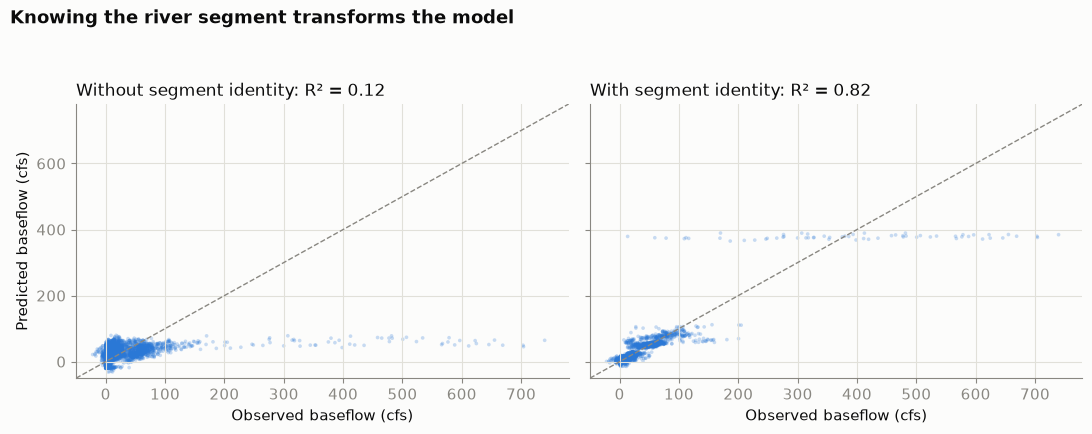

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True, sharex=True)
lims = [-50, 780]
for ax, pred, ytrue, ttl in [
        (axes[0], predA, test['Observed'], f'Without segment identity: R² = {r2A:.2f}'),
        (axes[1], predC, yteC, f'With segment identity: R² = {r2C:.2f}')]:
    ax.scatter(ytrue, pred, s=7, alpha=0.25, color=BLUE, edgecolors='none')
    ax.plot(lims, lims, color=MUTED, lw=1, ls='--')
    ax.set_xlabel('Observed baseflow (cfs)')
    ax.set_title(ttl, loc='left')
    ax.set_xlim(lims)
    ax.set_ylim(lims)
axes[0].set_ylabel('Predicted baseflow (cfs)')
fig.suptitle('Knowing the river segment transforms the model', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

### Coefficients and p values

We refit Model A and Model C with statsmodels on the full dataset to read coefficients and p values. Note the sign convention for pumping: pumping values are zero or negative, so a positive coefficient means that more pumping (a more negative value) predicts lower baseflow.


In [10]:
olsA = sm.OLS(df['Observed'], sm.add_constant(df[features])).fit()
print('Model A, full data R² =', round(olsA.rsquared, 3))
olsA.summary2().tables[1].round(4)

Model A, full data R² = 0.13


,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
const,54.6237,1.9090,28.6132,0.0000,50.8818,58.3657
Date,-0.0020,0.0001,-29.1870,0.0000,-0.0022,-0.0019
Evapotranspiration,-1.0386,0.1693,-6.1331,0.0000,-1.3705,-0.7067
Precipitation,1.5794,0.0444,35.5879,0.0000,1.4925,1.6664
Irrigation_pumping,5.3004,1.8313,2.8943,0.0038,1.7108,8.8900


In [11]:
olsC = sm.OLS(df['Observed'], sm.add_constant(X.astype(float))).fit()
print('Model C, full data R² =', round(olsC.rsquared, 3))
olsC.summary2().tables[1].loc[['const'] + features].round(4)

Model C, full data R² = 0.807


,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
const,13.4406,2.0374,6.5970,0.0000,9.4471,17.4341
Date,-0.0003,0.0000,-8.8994,0.0000,-0.0004,-0.0003
Evapotranspiration,-0.9455,0.0840,-11.2583,0.0000,-1.1102,-0.7809
Precipitation,0.5205,0.0391,13.3181,0.0000,0.4439,0.5971
Irrigation_pumping,2.7241,0.9113,2.9891,0.0028,0.9378,4.5103


## 4. Per segment regressions

A single pooled model forces one climate response on every river. Fitting a separate regression to each segment (keeping segments with at least 30 months of data, and dropping any predictor that is constant within a segment, such as pumping where no pumping occurred) lets each river have its own behavior.


In [12]:
rows = []
for seg, g in df.groupby('Segment_id'):
    if len(g) < 30:
        continue
    cols = [c for c in features if g[c].nunique() > 1]
    r = sm.OLS(g['Observed'], sm.add_constant(g[cols])).fit()
    row = {'Segment_id': seg, 'n': len(g), 'r2': r.rsquared, 'mean_bf': g['Observed'].mean()}
    for c in cols:
        row[f'coef_{c}'] = r.params[c]
        row[f'p_{c}'] = r.pvalues[c]
    rows.append(row)
per = pd.DataFrame(rows)
print('Segments modeled:', len(per))
print('R² quartiles:', per['r2'].quantile([0.25, 0.5, 0.75]).round(3).to_dict())
sig_pr = ((per['coef_Precipitation'] > 0) & (per['p_Precipitation'] < 0.05)).mean()
sig_dt = ((per['coef_Date'] < 0) & (per['p_Date'] < 0.05)).mean()
print(f'Share with significant positive precipitation effect: {sig_pr:.0%}')
print(f'Share with significant negative time trend: {sig_dt:.0%}')
pumped = per[per['coef_Irrigation_pumping'].notna()]
sig_pu = ((pumped['coef_Irrigation_pumping'] > 0) & (pumped['p_Irrigation_pumping'] < 0.05)).mean()
print(f'Pumped segments: {len(pumped)}; share with significant pumping effect in the expected direction: {sig_pu:.0%}')

Segments modeled: 41
R² quartiles: {0.25: 0.201, 0.5: 0.383, 0.75: 0.598}
Share with significant positive precipitation effect: 66%
Share with significant negative time trend: 44%
Pumped segments: 32; share with significant pumping effect in the expected direction: 69%


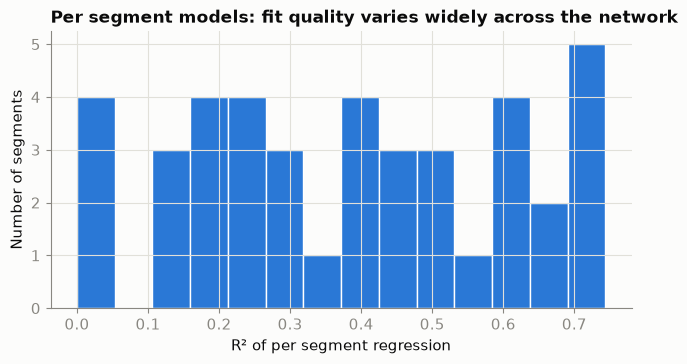

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.hist(per['r2'], bins=14, color=BLUE, edgecolor='white')
ax.set_xlabel('R² of per segment regression')
ax.set_ylabel('Number of segments')
ax.set_title('Per segment models: fit quality varies widely across the network', loc='left', fontweight='bold')
plt.show()

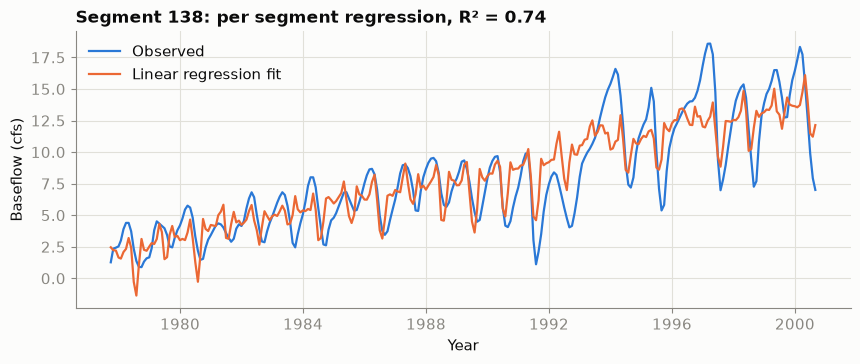

In [14]:
best = per.sort_values('r2', ascending=False).iloc[0]
seg_id = int(best['Segment_id'])
g = df[df['Segment_id'] == seg_id].sort_values('date')
cols = [c for c in features if g[c].nunique() > 1]
r = sm.OLS(g['Observed'], sm.add_constant(g[cols])).fit()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(g['date'], g['Observed'], color=BLUE, lw=1.6, label='Observed')
ax.plot(g['date'], r.fittedvalues, color=ORANGE, lw=1.6, label='Linear regression fit')
ax.set_ylabel('Baseflow (cfs)')
ax.set_xlabel('Year')
ax.legend(frameon=False)
ax.set_title(f'Segment {seg_id}: per segment regression, R² = {best["r2"]:.2f}',
             loc='left', fontweight='bold')
plt.show()

## 5. Conclusions

* The measured drivers alone (climate, pumping, and the date) explain little of pooled baseflow (test R² about 0.12) because the 42 segments sit on completely different flow scales.
* Adding segment identity as a categorical variable raises the test R² to about 0.82 and cuts RMSE from about 55 cfs to 25 cfs.
* Within segments, precipitation raises baseflow (significant and positive in about two thirds of segments) and evapotranspiration lowers it.
* In segments with irrigation pumping, about 69 percent show a statistically significant association between more pumping and lower baseflow, and the fixed cohort of long record segments shows baseflow declining from about 14 cfs in the 1940s to about 8 cfs by the late 1990s while pumping grew from near zero.
* Linear regression is a reasonable first model here, but it cannot capture the strong seasonal cycle or lagged groundwater responses, which is where most of the remaining error lives.
